# 01 · Preparación de los datos y análisis exploratorio

**Proyecto final:** un sistema que predice tiempos de entrega de pedidos, con una página web (frontend) conectada a un servidor (backend) que usa nuestros modelos.

**Datos:** usamos el *Brazilian E-Commerce Public Dataset by Olist*, publicado en Kaggle por Olist, una tienda online de Brasil. Tiene cerca de 100.000 pedidos reales hechos entre 2016 y 2018. Su licencia es CC BY-NC-SA 4.0 y lo descargamos el 15-11-2026.

**¿Qué hacemos en este cuaderno?**

1. Cargamos las 9 tablas del dataset y revisamos si tienen errores o datos vacíos.
2. Las juntamos en una sola tabla con **una fila por pedido**.
3. Limpiamos los datos y explicamos por qué tomamos cada decisión.
4. Exploramos los datos pensando en las tres preguntas que queremos responder:
   - **¿Cuántos días tardará en llegar un pedido?** (modelo de regresión)
   - **¿Llegará después de la fecha prometida?** (modelo de clasificación)
   - **¿Cuántos pedidos habrá por día?** (modelo de serie de tiempo)
5. Guardamos los datos limpios para usarlos en los siguientes cuadernos.

**Cómo ejecutarlo:** en Google Colab, la carpeta `proyecto` tiene que estar en *Mi unidad* de Google Drive; la primera celda pide permiso para entrar a Drive. En el computador, se abre con el entorno `.venv` del proyecto.

In [1]:
# Importamos las librerías: pandas y numpy para manejar los datos, matplotlib para los gráficos
# y statsmodels para analizar la serie de tiempo.
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller

# Este aviso de statsmodels habla de un cambio en una versión futura; no afecta nuestros resultados
warnings.filterwarnings("ignore", message="adfuller currently returns", category=FutureWarning)

# Si estamos en Colab, leemos los datos desde Google Drive; si no, desde la carpeta del proyecto
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/proyecto")  # cambiar si la carpeta está en otra ubicación de Drive
else:
    BASE = Path("..")

RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
MODELOS = BASE / "models"  # aquí guardamos lo que necesita la aplicación
if not (RAW / "olist_orders_dataset.csv").exists():
    raise FileNotFoundError(f"No se encontraron los CSV de Olist en {RAW.resolve()}. Revisa la ruta BASE.")
PROCESSED.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(exist_ok=True)
print(f"Leyendo datos desde: {RAW.resolve()}")

# Mostrar todas las columnas de las tablas y los números con 2 decimales
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.2f}".format)


def miles(n):
    """Escribe los números grandes con espacios para que se lean mejor: 96470 -> '96 470'."""
    return f"{n:,.0f}".replace(",", " ")


# Colores de los gráficos: azul = a tiempo, naranja = tarde, verde = fecha prometida.
# Los elegimos para que se distingan bien, también para personas con daltonismo.
SUPERFICIE, TINTA, TINTA_2, TENUE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRILLA, EJE = "#e1e0d9", "#c3c2b7"
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
RAMPA_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": TINTA, "axes.titlecolor": TINTA, "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": TINTA_2, "axes.edgecolor": EJE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "xtick.color": EJE, "ytick.color": EJE, "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": cycler(color=[AZUL, NARANJA, AQUA]),
})

Leyendo datos desde: D:\Buri\proyecto\data\raw


## 1. Cargamos las tablas

El dataset viene dividido en 9 tablas que se conectan entre sí. Por ejemplo, un pedido (`orders`) puede tener varios productos (`order_items`) y varios pagos (`payments`). Este esquema muestra cómo se relacionan (`──<` quiere decir "uno a muchos"):

```
customers ──< orders ──< order_items >── products ──> categorias (traducción)
                │              │
                │              └──> sellers
                ├──< payments
                └──< reviews

customers y sellers ──> geolocation (por prefijo de código postal, CEP)
```

Al leer los archivos tomamos dos decisiones:

- Convertimos las fechas a formato de fecha para poder restarlas (por ejemplo, para saber cuántos días tardó una entrega).
- Leímos los códigos postales (en Brasil se llaman CEP) como **texto** y no como números, porque algunos empiezan con 0 (como `01037`) y ese 0 se perdería.

In [2]:
# Leemos los 9 archivos CSV y mostramos un resumen de cada tabla
archivos = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "categorias": "product_category_name_translation.csv",
}
fechas = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "order_items": ["shipping_limit_date"],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}
tipos = {
    "customers": {"customer_zip_code_prefix": str},
    "sellers": {"seller_zip_code_prefix": str},
    "geolocation": {"geolocation_zip_code_prefix": str},
}
t = {nombre: pd.read_csv(RAW / archivo, parse_dates=fechas.get(nombre), dtype=tipos.get(nombre),
                         encoding="utf-8-sig")
     for nombre, archivo in archivos.items()}

pd.DataFrame({
    "filas": {n: len(d) for n, d in t.items()},
    "columnas": {n: d.shape[1] for n, d in t.items()},
    "celdas vacías": {n: int(d.isna().sum().sum()) for n, d in t.items()},
    "filas duplicadas": {n: int(d.duplicated().sum()) for n, d in t.items()},
})

,filas,columnas,celdas vacías,filas duplicadas
orders,99441,8,4908,0
order_items,112650,7,0,0
customers,99441,5,0,0
sellers,3095,4,0,0
products,32951,9,2448,0
payments,103886,5,0,0
reviews,99224,7,145903,0
geolocation,1000163,5,0,261831
categorias,71,2,0,0


**¿Qué vemos?** La tabla más grande es la de geolocalización, con más de un millón de filas, y es la única que tiene filas repetidas. Las demás no tienen duplicados.

### ¿Dónde hay datos vacíos?

In [3]:
# Listamos solo las columnas que tienen algún valor vacío
vacios = [{"tabla": nombre, "columna": col, "vacías": n, "% de la tabla": 100 * n / len(d)}
          for nombre, d in t.items() for col, n in d.isna().sum().items() if n]
pd.DataFrame(vacios)

,tabla,columna,vacías,% de la tabla
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,products,product_category_name,610,1.85
4,products,product_name_lenght,610,1.85
5,products,product_description_lenght,610,1.85
6,products,product_photos_qty,610,1.85
7,products,product_weight_g,2,0.01
8,products,product_length_cm,2,0.01
9,products,product_height_cm,2,0.01


**¿Qué vemos?**

- **Fechas vacías en los pedidos:** tiene sentido. Un pedido cancelado o que todavía va en camino no puede tener fecha de entrega. Lo confirmamos más abajo con el estado de cada pedido.
- **Productos:** hay 610 productos sin categoría, nombre, descripción ni fotos (son los mismos 610), y 2 sin peso ni medidas.
- **Reseñas:** casi todas tienen el título y el comentario vacíos, porque escribirlos es opcional. El puntaje de 1 a 5 estrellas nunca falta.

### ¿Las tablas se conectan bien?

Revisamos que cada fila apunte a algo que exista en la otra tabla. Por ejemplo, que cada producto vendido pertenezca a un pedido que existe.

In [4]:
# Contamos las filas "huérfanas": las que apuntan a algo que no existe en la otra tabla
o, it, c, s, p = (t[k] for k in ["orders", "order_items", "customers", "sellers", "products"])
pd.Series({
    "productos vendidos sin pedido": (~it["order_id"].isin(o["order_id"])).sum(),
    "productos vendidos sin ficha de producto": (~it["product_id"].isin(p["product_id"])).sum(),
    "productos vendidos sin vendedor": (~it["seller_id"].isin(s["seller_id"])).sum(),
    "pedidos sin cliente": (~o["customer_id"].isin(c["customer_id"])).sum(),
    "pedidos sin productos": (~o["order_id"].isin(it["order_id"])).sum(),
    "pedidos sin pago": (~o["order_id"].isin(t["payments"]["order_id"])).sum(),
    "pedidos sin reseña": (~o["order_id"].isin(t["reviews"]["order_id"])).sum(),
}, name="cantidad").to_frame()

,cantidad
productos vendidos sin pedido,0
productos vendidos sin ficha de producto,0
productos vendidos sin vendedor,0
pedidos sin cliente,0
pedidos sin productos,775
pedidos sin pago,1
pedidos sin reseña,768


In [5]:
# customer_id cambia en cada pedido; customer_unique_id identifica a la persona
print(f"customer_id distintos: {miles(c['customer_id'].nunique())}")
print(f"personas distintas (customer_unique_id): {miles(c['customer_unique_id'].nunique())}")

customer_id distintos: 99 441
personas distintas (customer_unique_id): 96 096


**¿Qué vemos?**

- Las tablas se conectan sin problemas: todos los productos vendidos tienen su pedido, su ficha y su vendedor.
- Hay 775 pedidos sin productos registrados. En la limpieza veremos que ninguno fue entregado, así que no nos afectan.
- Un detalle importante: `customer_id` no identifica a una persona, sino a un pedido. Para contar personas hay que usar `customer_unique_id`. Hay 3.345 pedidos más que personas, porque algunos clientes compraron más de una vez.

### ¿En qué estado están los pedidos?

In [6]:
# Cuántos pedidos hay en cada estado y cuántos de ellos tienen fecha de entrega
estado = o["order_status"].value_counts().to_frame("pedidos")
estado["%"] = 100 * estado["pedidos"] / len(o)
estado["con fecha de entrega"] = o.groupby("order_status")["order_delivered_customer_date"].count()
estado

,pedidos,%,con fecha de entrega
order_status,,,
delivered,96478,97.02,96470
shipped,1107,1.11,0
canceled,625,0.63,6
unavailable,609,0.61,0
invoiced,314,0.32,0
processing,301,0.30,0
created,5,0.01,0
approved,2,0.00,0


**¿Qué vemos?** El 97% de los pedidos fue entregado (`delivered`). Como esperábamos, casi solo los pedidos entregados tienen fecha de entrega, así que esas fechas vacías no son errores. Las excepciones son pocas: 8 pedidos "entregados" sin fecha y 6 cancelados que sí la tienen. Los sacamos en la limpieza.

## 2. Coordenadas y estados a partir del código postal

Para calcular la distancia entre el vendedor y el cliente necesitamos sus coordenadas (latitud y longitud). La tabla de geolocalización tiene más de un millón de filas porque cada código postal aparece muchas veces, con coordenadas un poco distintas. Para quedarnos con **un solo punto por código postal**:

- Quitamos las coordenadas que caen fuera de Brasil, porque son errores de registro.
- Usamos la **mediana** de las coordenadas y no el promedio, porque un punto mal ubicado mueve mucho el promedio, pero casi no mueve la mediana.

In [7]:
# Nos quedamos con un punto (latitud, longitud) por cada prefijo de código postal
geo = t["geolocation"]
en_brasil = geo["geolocation_lat"].between(-34, 5.5) & geo["geolocation_lng"].between(-74, -32)
geo_cep = (geo[en_brasil]
           .groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].median()
           .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"}))
geo_cep.index.name = "cep_prefijo"
print(f"Filas exactamente duplicadas: {miles(geo.duplicated().sum())}")
print(f"Coordenadas fuera de Brasil descartadas: {miles((~en_brasil).sum())}")
print(f"Prefijos de CEP con coordenadas: {miles(len(geo_cep))}")

Filas exactamente duplicadas: 261 831
Coordenadas fuera de Brasil descartadas: 31
Prefijos de CEP con coordenadas: 19 011


**¿Qué vemos?** Solo 31 coordenadas estaban fuera de Brasil. Al final tenemos coordenadas para 19.011 códigos postales.

### ¿Coinciden los estados con los códigos postales?

Comparamos el estado que dice cada vendedor y cada cliente con el estado al que pertenece su código postal.

In [8]:
# Para cada código postal buscamos su estado más frecuente y lo comparamos con el estado declarado
estado_cep = geo.groupby("geolocation_zip_code_prefix")["geolocation_state"].agg(lambda x: x.mode().iloc[0])

s = s.copy()
estado_segun_cep = s["seller_zip_code_prefix"].map(estado_cep)
inconsistente = estado_segun_cep.notna() & (estado_segun_cep != s["seller_state"])
print(f"Vendedores con estado inconsistente: {inconsistente.sum()} de {miles(len(s))} ({inconsistente.mean():.1%})")
display(s.loc[inconsistente, ["seller_zip_code_prefix", "seller_city", "seller_state"]]
        .assign(estado_segun_cep=estado_segun_cep[inconsistente]).head(6))
s.loc[inconsistente, "seller_state"] = estado_segun_cep[inconsistente]

estado_cliente_cep = c["customer_zip_code_prefix"].map(estado_cep)
print(f"Clientes con estado inconsistente: "
      f"{(estado_cliente_cep.notna() & (estado_cliente_cep != c['customer_state'])).sum()}")

# Guardamos también el estado de cada código postal: la aplicación lo usará para saber
# en qué estado están el cliente y el vendedor a partir de su código postal
geo_cep["estado"] = estado_cep.reindex(geo_cep.index)

Vendedores con estado inconsistente: 35 de 3 095 (1.1%)


,seller_zip_code_prefix,seller_city,seller_state,estado_segun_cep
70,95076,caxias do sul,SP,RS
114,21210,rio de janeiro,RN,RJ
198,85301,laranjeiras do sul,SP,PR
206,87360,goioere,SP,PR
275,86170,sertanopolis,SP,PR
311,85960,marechal candido rondon,SP,PR


Clientes con estado inconsistente: 0


**¿Qué vemos?** 35 vendedores (1,1%) tienen un estado que no coincide con su código postal. Al revisarlos, vimos que la **ciudad sí coincide con el código postal**: por ejemplo, Caxias do Sul está en Rio Grande do Sul (RS), pero el vendedor aparece en São Paulo (SP). Entonces el error está en el estado.

**¿Qué decidimos?** Corregir el estado de esos vendedores usando el estado de su código postal. En los clientes no encontramos este problema.

## 3. Juntamos todo en una fila por pedido

Nuestros modelos predicen **por pedido**, pero la información de cada pedido está repartida en varias tablas, y algunas tienen varias filas por pedido (un pedido puede tener varios productos o varios pagos). Por eso resumimos cada tabla así:

| Tabla | Cómo la resumimos por pedido |
|---|---|
| Productos del pedido | cuántos productos, precio total, flete total, peso y volumen totales |
| Producto principal | categoría y vendedor del producto **más caro** del pedido |
| Pagos | valor total, número de cuotas y forma de pago del pago más grande |
| Reseñas | puntaje de la reseña más reciente (solo para explorar; no lo usamos para predecir) |

Antes completamos los productos con datos faltantes:

- **Sin categoría (610 productos):** les pusimos la categoría `sin_categoria`, para no perder esos pedidos.
- **Sin peso ni medidas (2 productos):** usamos la mediana de los productos de su misma categoría.

In [9]:
# Traducimos las categorías al inglés y completamos los datos faltantes de los productos
prod = p.copy()
traduccion = t["categorias"].set_index("product_category_name")["product_category_name_english"]
prod["categoria"] = (prod["product_category_name"].map(traduccion)
                     .fillna(prod["product_category_name"])
                     .fillna("sin_categoria"))
for col in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    mediana_categoria = prod.groupby("categoria")[col].transform("median")
    prod[col] = prod[col].fillna(mediana_categoria).fillna(prod[col].median())
prod["volumen_cm3"] = prod["product_length_cm"] * prod["product_height_cm"] * prod["product_width_cm"]

sin_traduccion = prod.loc[prod["product_category_name"].notna()
                          & ~prod["product_category_name"].isin(traduccion.index), "product_category_name"]
print("Categorías sin traducción (se deja el nombre en portugués):", sorted(sin_traduccion.unique()))
print(f"Productos sin categoría: {miles((prod['categoria'] == 'sin_categoria').sum())}")

Categorías sin traducción (se deja el nombre en portugués): ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Productos sin categoría: 610


In [10]:
# Resumimos productos, pagos y reseñas para tener un solo valor por pedido
items = it.merge(prod[["product_id", "categoria", "product_weight_g", "volumen_cm3"]], on="product_id", how="left")
resumen_items = items.groupby("order_id").agg(
    n_items=("order_item_id", "size"),
    n_productos=("product_id", "nunique"),
    n_vendedores=("seller_id", "nunique"),
    precio_total=("price", "sum"),
    flete_total=("freight_value", "sum"),
    peso_total_g=("product_weight_g", "sum"),
    volumen_total_cm3=("volumen_cm3", "sum"),
)
principal = (items.sort_values(["order_id", "price"], ascending=[True, False])
             .drop_duplicates("order_id")
             .set_index("order_id")[["seller_id", "categoria"]])

pagos = t["payments"]
resumen_pagos = pagos.groupby("order_id").agg(pago_total=("payment_value", "sum"),
                                              cuotas=("payment_installments", "max"))
resumen_pagos["tipo_pago"] = (pagos.sort_values(["order_id", "payment_value"], ascending=[True, False])
                              .drop_duplicates("order_id")
                              .set_index("order_id")["payment_type"])

resena = (t["reviews"].sort_values("review_answer_timestamp")
          .drop_duplicates("order_id", keep="last")
          .set_index("order_id")["review_score"])

print(f"Pedidos con más de un producto: {(resumen_items['n_items'] > 1).mean():.1%}")
print(f"Pedidos con más de un vendedor: {(resumen_items['n_vendedores'] > 1).mean():.1%}")

Pedidos con más de un producto: 9.9%
Pedidos con más de un vendedor: 1.3%


Casi el 10% de los pedidos tiene más de un producto, pero solo el 1,3% tiene productos de más de un vendedor.

In [11]:
# Unimos todo en la tabla "pedidos" (una fila por pedido)
clientes = c.set_index("customer_id")[["customer_unique_id", "customer_zip_code_prefix",
                                       "customer_city", "customer_state"]]
vendedores = s.set_index("seller_id")[["seller_zip_code_prefix", "seller_city", "seller_state"]]

pedidos = (o.join(clientes, on="customer_id")
           .join(resumen_items, on="order_id")
           .join(principal, on="order_id")
           .join(vendedores, on="seller_id")
           .join(resumen_pagos, on="order_id")
           .join(resena, on="order_id")
           .join(geo_cep.add_prefix("cliente_"), on="customer_zip_code_prefix")
           .join(geo_cep.add_prefix("vendedor_"), on="seller_zip_code_prefix"))

# Comprobamos que al unir no se haya duplicado ni perdido ningún pedido
assert pedidos["order_id"].is_unique and len(pedidos) == len(o)

### Creamos variables nuevas

A partir de los datos originales calculamos algunas variables que creemos que ayudan a predecir:

- `distancia_km`: distancia en línea recta entre el vendedor y el cliente. La calculamos con la fórmula de *haversine*, que mide distancias sobre la superficie de la Tierra a partir de las coordenadas.
- `mismo_estado`: vale 1 si el vendedor y el cliente están en el mismo estado y 0 si no.
- `dias_prometidos`: cuántos días le promete Olist al cliente para la entrega.
- `mes`, `dia_semana` y `hora`: cuándo se hizo la compra.

Todas se conocen **en el momento de la compra**. Esto es importante: la aplicación tiene que poder calcularlas con los datos que escriba el usuario, antes de que el pedido llegue.

In [12]:
# Fórmula de haversine: distancia en km entre dos puntos a partir de su latitud y longitud
def haversine_km(lat1, lng1, lat2, lng2):
    """Distancia en línea recta (km) entre dos puntos de la Tierra."""
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


# Calculamos las variables nuevas y mostramos 3 pedidos de ejemplo
compra = pedidos["order_purchase_timestamp"]
pedidos["distancia_km"] = haversine_km(pedidos["cliente_lat"], pedidos["cliente_lng"],
                                       pedidos["vendedor_lat"], pedidos["vendedor_lng"])
pedidos["mismo_estado"] = (pedidos["customer_state"] == pedidos["seller_state"]).astype(int)
pedidos["dias_prometidos"] = (pedidos["order_estimated_delivery_date"] - compra).dt.total_seconds() / 86400
pedidos["anio_mes"] = compra.dt.to_period("M")
pedidos["mes"] = compra.dt.month
pedidos["dia_semana"] = compra.dt.day_of_week
pedidos["hora"] = compra.dt.hour
pedidos.head(3).T

,0,1,2
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49
order_approved_at,2017-10-02 11:07:15,2018-07-26 03:24:27,2018-08-08 08:55:23
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00
customer_unique_id,7c396fd4830fd04220f754e42b4e5bff,af07308b275d755c9edb36a90c618231,3a653a41f6f9fc3d2a113cf8398680e8
customer_zip_code_prefix,03149,47813,75265


## 4. Limpieza de los datos

### 4.1 ¿Hasta qué fecha están completas las entregas?

Antes de limpiar quisimos revisar algo: si los datos se descargaron en una fecha determinada, los pedidos comprados poco antes de esa fecha solo aparecerían como "entregados" si llegaron rápido. Los que iban a tardar más todavía no habrían llegado.

In [13]:
# Contamos cuántas entregas hay en cada mes y vemos cuánto tardaron los pedidos según el mes de compra
mes_entrega = pedidos["order_delivered_customer_date"].dt.to_period("M").value_counts().sort_index()
mes_entrega.index = mes_entrega.index.astype(str)
display(mes_entrega.loc["2018-05":].to_frame("entregas registradas en el mes"))

dias_tmp = (pedidos["order_delivered_customer_date"] - compra).dt.total_seconds() / 86400
percentiles = dias_tmp.groupby(pedidos["anio_mes"]).quantile([0.5, 0.9, 0.99]).unstack()
percentiles.columns = ["mediana", "percentil 90", "percentil 99"]
percentiles.index = percentiles.index.astype(str)
percentiles.loc["2017-10":"2018-08"]

,entregas registradas en el mes
order_delivered_customer_date,
2018-05,7111
2018-06,6829
2018-07,5839
2018-08,8314
2018-09,56
2018-10,3


,mediana,percentil 90,percentil 99
anio_mes,,,
2017-10,10.26,20.09,39.26
2017-11,12.70,27.21,51.77
2017-12,13.14,28.26,49.77
2018-01,11.83,25.46,49.48
2018-02,14.27,31.02,57.95
2018-03,13.37,32.19,54.28
2018-04,9.31,21.42,44.49
2018-05,9.15,21.45,35.87
2018-06,7.96,15.91,34.20


**¿Qué vemos?** Hasta agosto de 2018 hay entre 5.800 y 8.300 entregas por mes, pero en septiembre solo 56 y en octubre 3. Esto quiere decir que **los datos se extrajeron a fines de agosto de 2018**. Por eso los pedidos comprados en agosto de 2018 parecen más rápidos de lo que fueron: el 99% de ellos llegó en menos de 21 días (eso es el "percentil 99"), cuando en los meses anteriores ese valor estaba entre 31 y 58 días.

**¿Qué decidimos?**

- Sacar los pedidos **comprados desde el 1 de agosto de 2018**. Si los dejábamos, el modelo aprendería que las entregas recientes son más cortas de lo que realmente fueron. Julio de 2018 también se ve un poco afectado (31 días), pero menos, así que lo dejamos.
- Sacar los pedidos de **2016**: son solo 263, corresponden al inicio de la tienda y entre noviembre y diciembre de 2016 casi no hay pedidos (1 en total).

### 4.2 Reglas de limpieza

Para predecir los días de entrega y si un pedido llega tarde necesitamos saber **cuándo llegó**, así que solo nos sirven los pedidos entregados. Aplicamos estas reglas en orden; cada pedido se cuenta en la primera regla que lo saca:

In [14]:
# Aplicamos las reglas una por una y contamos cuántos pedidos saca cada una
reglas = {
    "no entregado o sin fecha de entrega": (pedidos["order_status"].ne("delivered")
                                            | pedidos["order_delivered_customer_date"].isna()),
    "sin productos registrados": pedidos["n_items"].isna(),
    "llegó al transportista antes de la compra": pedidos["order_delivered_carrier_date"] < compra,
    "llegó al cliente antes que al transportista": (pedidos["order_delivered_customer_date"]
                                                    < pedidos["order_delivered_carrier_date"]),
    "comprado en 2016 (inicio de la operación, pocos pedidos)": compra < pd.Timestamp("2017-01-01"),
    "comprado desde agosto de 2018 (seguimiento incompleto)": compra >= pd.Timestamp("2018-08-01"),
}
eliminar = pd.Series(False, index=pedidos.index)
registro = []
for regla, condicion in reglas.items():
    registro.append({"regla": regla, "pedidos": int((condicion & ~eliminar).sum())})
    eliminar |= condicion
entregados = pedidos[~eliminar].copy()
registro.append({"regla": "quedan para los modelos de regresión y clasificación", "pedidos": len(entregados)})
pd.DataFrame(registro)

,regla,pedidos
0,no entregado o sin fecha de entrega,2971
1,sin productos registrados,0
2,llegó al transportista antes de la compra,165
3,llegó al cliente antes que al transportista,23
4,"comprado en 2016 (inicio de la operación, poco...",263
5,comprado desde agosto de 2018 (seguimiento inc...,6306
6,quedan para los modelos de regresión y clasifi...,89713


**¿Qué vemos?** La mayoría de los pedidos que sacamos son los que no fueron entregados (2.971) y los de agosto de 2018 (6.306). Las fechas imposibles, como un pedido que llegó al transportista antes de que lo compraran, son pocas (188 en total); las eliminamos porque muestran un error de registro. Nos quedan **89.713 pedidos**.

### ¿Qué queremos predecir?

- **`dias_entrega`** (para el modelo de regresión): cuántos días pasaron desde la compra hasta que el pedido llegó.
- **`tarde`** (para el modelo de clasificación): vale 1 si el pedido llegó **después del día prometido** y 0 si llegó a tiempo.

In [15]:
# Calculamos las dos variables que queremos predecir
entregados["dias_entrega"] = ((entregados["order_delivered_customer_date"] - entregados["order_purchase_timestamp"])
                              .dt.total_seconds() / 86400)
entregados["tarde"] = (entregados["order_delivered_customer_date"].dt.normalize()
                       > entregados["order_estimated_delivery_date"]).astype(int)
print(f"Pedidos sin coordenadas (distancia vacía): {miles(entregados['distancia_km'].isna().sum())} "
      f"({entregados['distancia_km'].isna().mean():.1%})")
entregados[["dias_entrega", "dias_prometidos", "tarde"]].describe()

Pedidos sin coordenadas (distancia vacía): 449 (0.5%)


,dias_entrega,dias_prometidos,tarde
count,89713.00,89713.00,89713.00
mean,12.89,24.25,0.07
std,9.71,8.25,0.25
min,0.53,2.01,0.00
25%,6.96,19.18,0.00
50%,10.63,23.47,0.00
75%,16.08,28.57,0.00
max,209.63,155.14,1.00


**Pedidos sin distancia (0,5%).** Su código postal no aparece en la tabla de coordenadas. No los rellenamos aquí, sino en el siguiente cuaderno, usando la mediana de los datos de entrenamiento. Si lo hiciéramos ahora con todos los datos, estaríamos usando información de los pedidos con los que después vamos a evaluar el modelo. Eso se llama **fuga de datos**: el modelo "ve" información que en la vida real no tendría.

### ¿Qué hacemos con los pedidos que tardaron muchísimo?

Algunos pedidos tardaron meses. Con la regla del rango intercuartílico (IQR), que marca los valores que se alejan mucho de la mayoría, buscamos los pedidos **atípicos** y revisamos si son errores o casos reales.

In [16]:
# Marcamos como atípicos los pedidos que pasan el límite del rango intercuartílico y los comparamos con el resto
q1, q3 = entregados["dias_entrega"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
atipico = entregados["dias_entrega"] > limite
print(f"Límite para considerar un pedido atípico (regla IQR): {limite:.1f} días -> "
      f"{miles(atipico.sum())} pedidos ({atipico.mean():.1%})")
print(f"Llegaron tarde: {entregados.loc[atipico, 'tarde'].mean():.0%} de los atípicos "
      f"vs {entregados['tarde'].mean():.1%} del total")
print(f"Distancia mediana: {entregados.loc[atipico, 'distancia_km'].median():.0f} km en los atípicos "
      f"vs {entregados['distancia_km'].median():.0f} km en el total")
pd.DataFrame({
    "% de los atípicos": 100 * entregados.loc[atipico, "customer_state"].value_counts(normalize=True),
    "% del total": 100 * entregados["customer_state"].value_counts(normalize=True),
}).sort_values("% de los atípicos", ascending=False).head(8)

Límite para considerar un pedido atípico (regla IQR): 29.8 días -> 4 601 pedidos (5.1%)
Llegaron tarde: 79% de los atípicos vs 6.8% del total
Distancia mediana: 821 km en los atípicos vs 439 km en el total


,% de los atípicos,% del total
customer_state,,
RJ,25.47,12.90
SP,11.21,41.45
BA,8.74,3.45
RS,7.54,5.60
MG,5.76,11.81
SC,4.74,3.71
PA,4.63,1.00
CE,4.26,1.36


**¿Qué vemos?** El 5,1% de los pedidos tardó más de 29,8 días, pero no parecen errores:

- El 79% de ellos llegó tarde, cuando en general solo llega tarde el 6,8%. Son retrasos reales.
- Recorrieron casi el doble de distancia (821 km contra 439 km).
- Muchos van a estados lejanos o con más problemas de reparto. Río de Janeiro tiene el 25% de los atípicos, pero solo el 13% de los pedidos.

**¿Qué decidimos?** **Dejarlos.** Si los sacábamos, el modelo aprendería a prometer tiempos demasiado optimistas justo en esas regiones. Para que estos casos no pesen demasiado al entrenar, en el modelado vamos a usar el logaritmo de los días (ver 5.1) y vamos a usar como métrica principal el MAE, que se ve menos afectado por los valores extremos.

## 5. Exploración de los datos

### 5.1 ¿Cuántos días suelen tardar los pedidos?

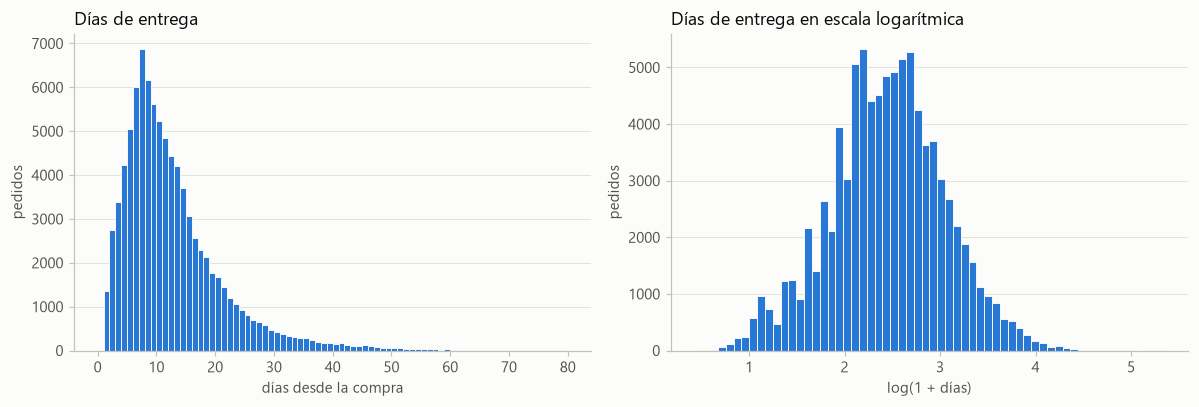

Asimetría (0 = simétrica): 3.82 en días -> 0.01 con logaritmo
(El gráfico de la izquierda se corta en 80 días; hay 106 pedidos por encima.)


In [17]:
# Histograma de los días de entrega: en días normales y con logaritmo
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(entregados["dias_entrega"], bins=np.arange(0, 81, 1), color=AZUL, edgecolor=SUPERFICIE, linewidth=0.6)
ax[0].set(title="Días de entrega", xlabel="días desde la compra", ylabel="pedidos")
ax[1].hist(np.log1p(entregados["dias_entrega"]), bins=60, color=AZUL, edgecolor=SUPERFICIE, linewidth=0.6)
ax[1].set(title="Días de entrega en escala logarítmica", xlabel="log(1 + días)", ylabel="pedidos")
for a in ax:
    a.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(f"Asimetría (0 = simétrica): {entregados['dias_entrega'].skew():.2f} en días -> "
      f"{np.log1p(entregados['dias_entrega']).skew():.2f} con logaritmo")
print(f"(El gráfico de la izquierda se corta en 80 días; hay {miles((entregados['dias_entrega'] > 80).sum())} pedidos por encima.)")

**¿Qué vemos?** La mayoría de los pedidos llega en una o dos semanas (la mediana es de 10,6 días), pero hay una "cola" larga hacia la derecha, con pedidos que tardaron meses. Por eso la distribución es muy asimétrica (3,8). Cuando aplicamos logaritmo, `log(1 + días)`, queda casi simétrica (0,01).

**¿Qué decidimos?** En el modelo de regresión vamos a probar entrenar con el logaritmo de los días y después convertir la predicción de vuelta a días. Así los pedidos muy tardíos no dominan el entrenamiento.

### 5.2 ¿Los pedidos que viajan más lejos tardan más?

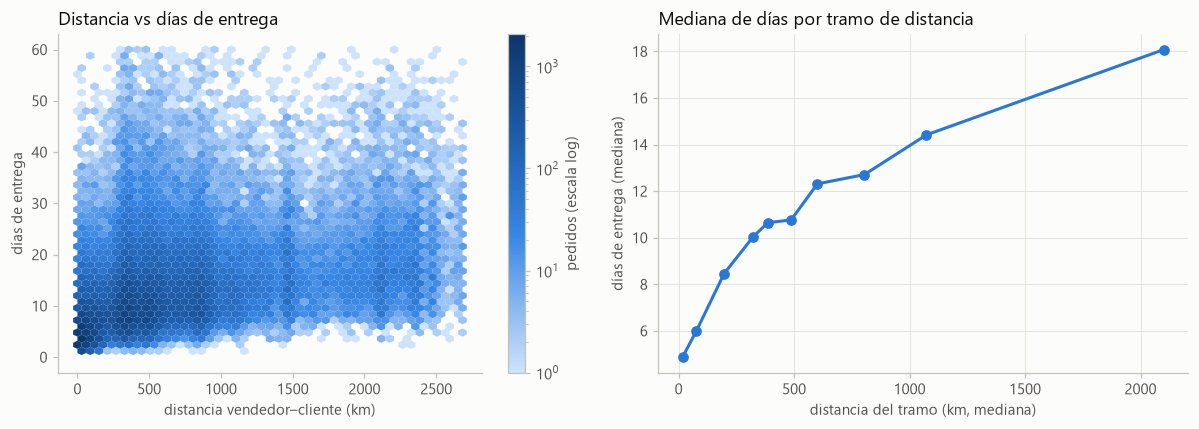

Correlación de Spearman entre distancia y días de entrega: 0.54


,km_mediana,dias_mediana,pct_tarde
distancia_km,,,
"(-0.001, 36.69]",17.02,4.87,3.23
"(36.69, 122.446]",76.47,5.99,4.20
"(122.446, 283.394]",196.89,8.46,4.91
"(283.394, 350.157]",321.42,10.02,6.93
"(350.157, 439.059]",385.74,10.64,6.83
"(439.059, 535.944]",487.00,10.76,6.93
"(535.944, 702.334]",601.00,12.31,7.95
"(702.334, 881.081]",804.71,12.71,6.93
"(881.081, 1463.47]",1072.65,14.41,8.12


In [18]:
# Relación entre distancia y días: mapa de densidad a la izquierda y mediana por tramos de distancia a la derecha
con_dist = entregados.dropna(subset=["distancia_km"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hb = ax[0].hexbin(con_dist["distancia_km"], con_dist["dias_entrega"], gridsize=45, bins="log", mincnt=1,
                  extent=(0, con_dist["distancia_km"].quantile(0.995), 0, 60), cmap=RAMPA_AZUL, linewidths=0)
fig.colorbar(hb, ax=ax[0], label="pedidos (escala log)")
ax[0].set(title="Distancia vs días de entrega", xlabel="distancia vendedor–cliente (km)", ylabel="días de entrega")
ax[0].grid(False)

tramos = (con_dist.groupby(pd.qcut(con_dist["distancia_km"], 10), observed=True)
          .agg(km_mediana=("distancia_km", "median"), dias_mediana=("dias_entrega", "median"),
               pct_tarde=("tarde", "mean")))
tramos["pct_tarde"] *= 100
ax[1].plot(tramos["km_mediana"], tramos["dias_mediana"], marker="o", markersize=6, color=AZUL)
ax[1].set(title="Mediana de días por tramo de distancia", xlabel="distancia del tramo (km, mediana)",
          ylabel="días de entrega (mediana)")
plt.tight_layout()
plt.show()
rho = con_dist[["distancia_km", "dias_entrega"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman entre distancia y días de entrega: {rho:.2f}")
tramos

**¿Qué vemos?** Sí. La distancia es la variable más relacionada con la demora: su correlación de Spearman es de 0,54 (en una escala de −1 a 1). Dividimos los pedidos en 10 grupos según la distancia:

- En el 10% más cercano (unos 17 km), la mitad de los pedidos llega en menos de 4,9 días.
- En el 10% más lejano (unos 2.100 km), la mediana sube a 18,1 días.
- El porcentaje de pedidos que llega tarde también sube, de 3,2% a 12,2%.

La relación no es una línea recta: los días suben rápido en los primeros 300 km y más lento después. Por eso pensamos que los modelos basados en árboles de decisión, que pueden seguir curvas, van a funcionar mejor que un modelo lineal.

### 5.3 ¿Importa dónde están el vendedor y el cliente?

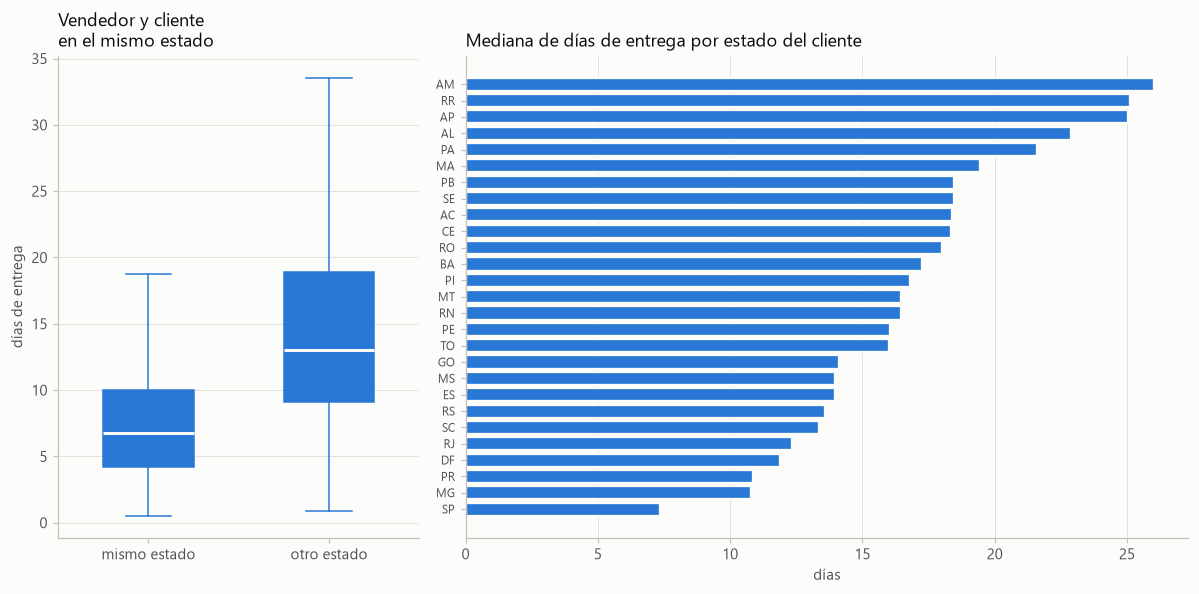

,count,mean,std,min,25%,50%,75%,max
mismo_estado,,,,,,,,
0,58104.00,15.49,10.18,0.86,9.09,13.06,18.88,209.63
1,31609.00,8.10,6.45,0.53,4.23,6.79,10.04,191.46


In [19]:
# Días de entrega según si el vendedor y el cliente están en el mismo estado, y según el estado del cliente
fig, ax = plt.subplots(1, 2, figsize=(11, 5.5), gridspec_kw={"width_ratios": [1, 2]})
grupos = [entregados.loc[entregados["mismo_estado"] == v, "dias_entrega"] for v in (1, 0)]
ax[0].boxplot(grupos, showfliers=False, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=AZUL, color=AZUL), medianprops=dict(color=SUPERFICIE, linewidth=2),
              whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
ax[0].set_xticks([1, 2], ["mismo estado", "otro estado"])
ax[0].set(title="Vendedor y cliente\nen el mismo estado", ylabel="días de entrega")
ax[0].grid(axis="x", visible=False)

por_estado = entregados.groupby("customer_state")["dias_entrega"].median().sort_values()
ax[1].barh(por_estado.index, por_estado.values, color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5)
ax[1].set(title="Mediana de días de entrega por estado del cliente", xlabel="días")
ax[1].grid(axis="y", visible=False)
ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
entregados.groupby("mismo_estado")["dias_entrega"].describe()

**¿Qué vemos?** Mucho. Cuando el vendedor y el cliente están en el mismo estado, la mediana es de 6,8 días; cuando están en estados distintos, sube a 13,1 días. Por estado, São Paulo es el más rápido (unos 7 días), porque ahí están la mayoría de los vendedores. Los estados del norte, como Amazonas, Roraima y Amapá, superan los 24 días.

**¿Qué decidimos?** Usar el estado del cliente y el del vendedor como variables del modelo. Como son categorías (SP, RJ, MG…) y no números, hay que convertirlas: vamos a usar *one-hot encoding*, que crea una columna de 0 y 1 para cada estado.

### 5.4 ¿Qué tan seguido llegan tarde los pedidos?

In [20]:
# Cuántos pedidos llegaron a tiempo y cuántos tarde
balance = entregados["tarde"].value_counts().rename({0: "a tiempo", 1: "tarde"}).to_frame("pedidos")
balance["%"] = 100 * balance["pedidos"] / len(entregados)
balance

,pedidos,%
tarde,,
a tiempo,83577,93.16
tarde,6136,6.84


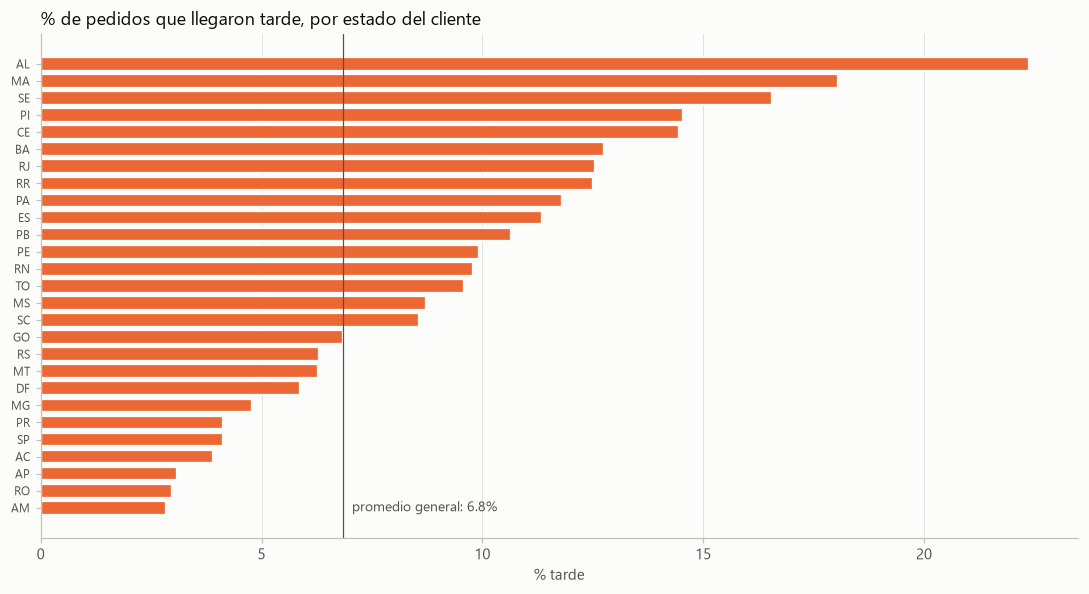

In [21]:
# Porcentaje de pedidos que llegaron tarde en cada estado
por_estado_tarde = (entregados.groupby("customer_state")["tarde"].agg(pct_tarde="mean", pedidos="size")
                    .assign(pct_tarde=lambda d: 100 * d["pct_tarde"]).sort_values("pct_tarde"))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(por_estado_tarde.index, por_estado_tarde["pct_tarde"], color=NARANJA, edgecolor=SUPERFICIE, linewidth=1.5)
ax.axvline(100 * entregados["tarde"].mean(), color=TINTA_2, linewidth=0.8)
ax.annotate(f"promedio general: {100 * entregados['tarde'].mean():.1f}%", xy=(100 * entregados["tarde"].mean(), 0),
            xytext=(6, 0), textcoords="offset points", va="center", color=TINTA_2, fontsize=9)
ax.set(title="% de pedidos que llegaron tarde, por estado del cliente", xlabel="% tarde")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

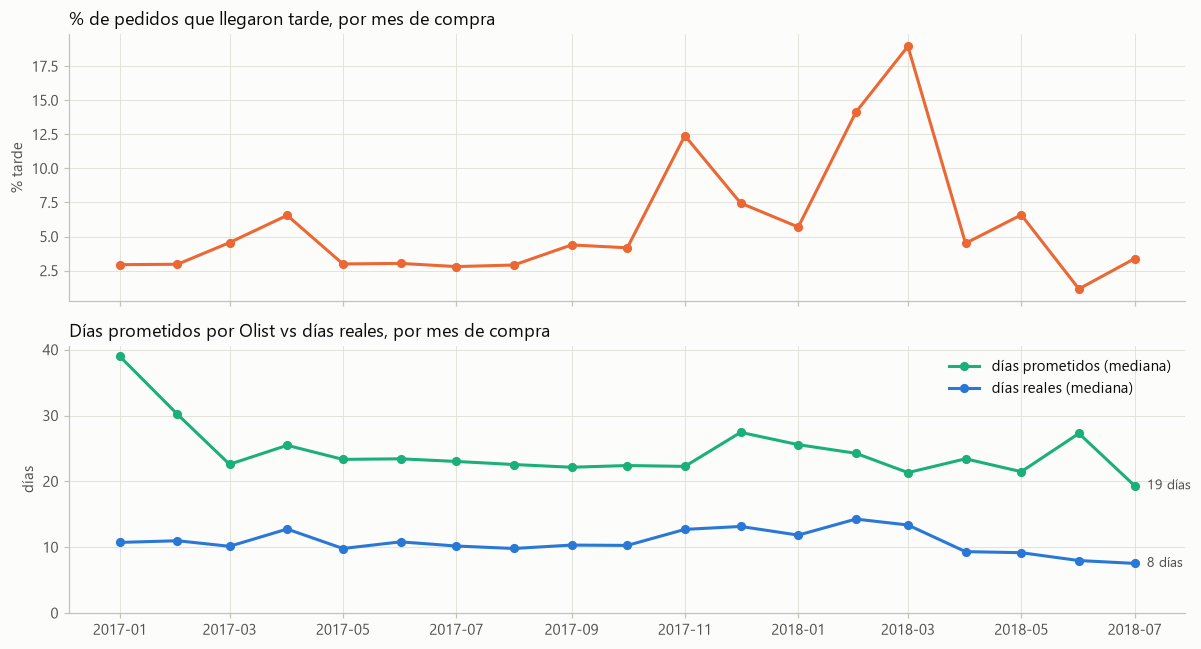

,pedidos,pct_tarde,dias_reales,dias_prometidos
anio_mes,,,,
2017-01,749,2.94,10.72,38.98
2017-02,1651,2.97,10.97,30.18
2017-03,2545,4.56,10.13,22.59
2017-04,2303,6.56,12.75,25.47
2017-05,3544,2.99,9.79,23.33
2017-06,3134,3.03,10.80,23.42
2017-07,3861,2.80,10.17,23.02
2017-08,4191,2.91,9.80,22.55
2017-09,4150,4.39,10.31,22.14


In [22]:
# Mes a mes: porcentaje de pedidos tarde, días prometidos y días reales
mensual = (entregados.groupby("anio_mes")
           .agg(pedidos=("order_id", "size"), pct_tarde=("tarde", "mean"),
                dias_reales=("dias_entrega", "median"), dias_prometidos=("dias_prometidos", "median")))
mensual["pct_tarde"] *= 100
x = mensual.index.to_timestamp()

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(x, mensual["pct_tarde"], marker="o", markersize=5, color=NARANJA)
ax[0].set(title="% de pedidos que llegaron tarde, por mes de compra", ylabel="% tarde")
ax[1].plot(x, mensual["dias_prometidos"], marker="o", markersize=5, color=AQUA, label="días prometidos (mediana)")
ax[1].plot(x, mensual["dias_reales"], marker="o", markersize=5, color=AZUL, label="días reales (mediana)")
for col, color in [("dias_prometidos", AQUA), ("dias_reales", AZUL)]:
    ax[1].annotate(f"{mensual[col].iloc[-1]:.0f} días", xy=(x[-1], mensual[col].iloc[-1]), xytext=(8, 0),
                   textcoords="offset points", va="center", color=TINTA_2, fontsize=9)
ax[1].set(title="Días prometidos por Olist vs días reales, por mes de compra", ylabel="días", ylim=(0, None))
ax[1].legend(loc="upper right")
plt.tight_layout()
plt.show()
mensual

**¿Qué vemos?**

- **Muy pocos pedidos llegan tarde:** solo el 6,8%. A esto se le llama **desbalance de clases** y es una trampa: un modelo que siempre diga "a tiempo" acertaría el 93,2% de las veces sin servir para nada. Por eso, en el modelo de clasificación no vamos a mirar solo el porcentaje de aciertos (*accuracy*). También vamos a usar el *recall* (de los pedidos que sí llegaron tarde, cuántos detecta el modelo), la precisión, el F1 y el AUC.
- **Depende mucho de la región:** en Amazonas llega tarde cerca del 3% de los pedidos y en Alagoas más del 22%. Nos llamó la atención que no depende solo de la distancia: en el norte Olist promete plazos muy largos y casi siempre cumple, mientras que en el nordeste y en Río de Janeiro falla más.
- **Depende mucho de la época:** en noviembre de 2017 (Black Friday) llegó tarde el 12,4%, y en febrero y marzo de 2018 el 14,1% y el 19,0%. En los meses tranquilos, cerca del 3%. Además, a mediados de 2018 las entregas se hicieron más rápidas: la mediana bajó de 13–14 días en febrero y marzo a 7,5 días en julio.

**¿Qué decidimos?** Como el comportamiento cambia con el tiempo, vamos a separar los datos **por fecha**: entrenar los modelos con los meses más antiguos y probarlos con los más recientes, en lugar de mezclar los pedidos al azar. Así la evaluación se parece más a usar el modelo en la vida real, donde siempre se predice el futuro.

### 5.5 ¿Qué tan buena es la fecha que promete Olist?

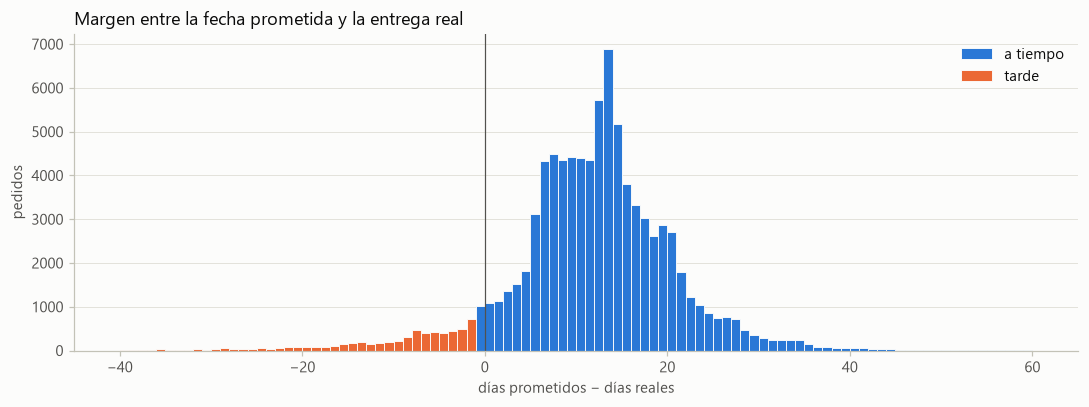

Margen mediano: 12.1 días antes de lo prometido
Error promedio (MAE) si usamos la fecha prometida por Olist como predicción: 13.0 días
Error promedio (MAE) si respondemos siempre la mediana (10.6 días): 6.2 días


In [23]:
# Diferencia entre los días prometidos y los días reales de cada pedido
margen = entregados["dias_prometidos"] - entregados["dias_entrega"]
bins = np.arange(-40, 61, 1)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(margen[entregados["tarde"] == 0], bins=bins, color=AZUL, edgecolor=SUPERFICIE, linewidth=0.6, label="a tiempo")
ax.hist(margen[entregados["tarde"] == 1], bins=bins, color=NARANJA, edgecolor=SUPERFICIE, linewidth=0.6, label="tarde")
ax.axvline(0, color=TINTA_2, linewidth=0.8)
ax.set(title="Margen entre la fecha prometida y la entrega real", xlabel="días prometidos − días reales",
       ylabel="pedidos")
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

mae_olist = margen.abs().mean()
mediana = entregados["dias_entrega"].median()
mae_mediana = (entregados["dias_entrega"] - mediana).abs().mean()
print(f"Margen mediano: {margen.median():.1f} días antes de lo prometido")
print(f"Error promedio (MAE) si usamos la fecha prometida por Olist como predicción: {mae_olist:.1f} días")
print(f"Error promedio (MAE) si respondemos siempre la mediana ({mediana:.1f} días): {mae_mediana:.1f} días")

**¿Qué vemos?** Olist promete fechas con mucho margen: en la mitad de los pedidos, la entrega llega 12 días o más antes de lo prometido. Suponemos que lo hace a propósito, para casi nunca quedar mal con el cliente. Pero como "predicción" de cuántos días tardará un pedido es mala: se equivoca 13,0 días en promedio, el doble que si respondiéramos siempre la mediana (6,2 días).

**¿Qué decidimos?** Usar estos dos valores como **punto de comparación** (*baseline*) para nuestro modelo de regresión: si no logra equivocarse menos de 6,2 días en promedio, no vale la pena. En el siguiente cuaderno los volvemos a calcular con los datos de prueba.

### 5.6 ¿Los clientes se molestan cuando el pedido llega tarde?

La reseña se escribe **después** de recibir el pedido, así que no podemos usarla para predecir. Pero nos sirve para mostrar por qué es importante predecir los retrasos.

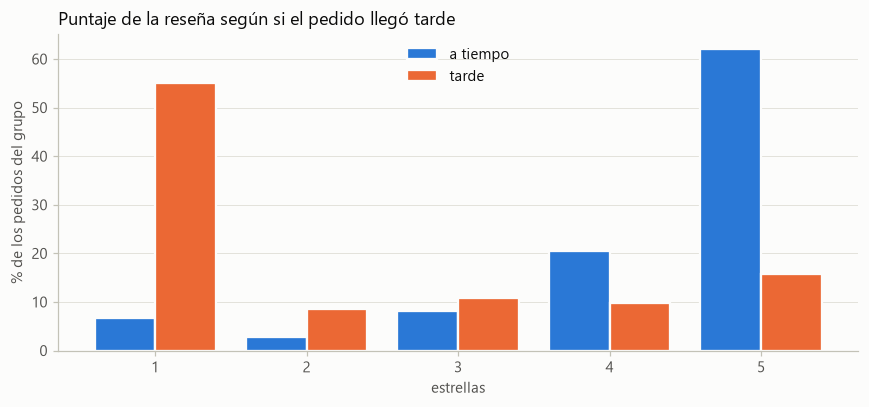

tarde
a tiempo   4.28
tarde      2.22


tarde,a tiempo,tarde
review_score,,
1,6.68,55.05
2,2.69,8.65
3,8.18,10.83
4,20.45,9.80
5,62.01,15.67


In [24]:
# Cómo se reparten las estrellas de la reseña en los pedidos a tiempo y en los pedidos tarde
dist_resena = (entregados.dropna(subset=["review_score"])
               .astype({"review_score": int})
               .groupby("tarde")["review_score"].value_counts(normalize=True)
               .unstack(0).rename(columns={0: "a tiempo", 1: "tarde"}) * 100)
estrellas = dist_resena.index.to_numpy()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(estrellas - 0.2, dist_resena["a tiempo"], width=0.4, color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5, label="a tiempo")
ax.bar(estrellas + 0.2, dist_resena["tarde"], width=0.4, color=NARANJA, edgecolor=SUPERFICIE, linewidth=1.5, label="tarde")
ax.set(title="Puntaje de la reseña según si el pedido llegó tarde", xlabel="estrellas",
       ylabel="% de los pedidos del grupo", xticks=estrellas)
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(entregados.groupby("tarde")["review_score"].mean().rename({0: "a tiempo", 1: "tarde"}).round(2).to_string())
dist_resena

**¿Qué vemos?** Sí, y mucho. Cuando el pedido llega tarde, el promedio de la reseña baja de 4,28 a 2,22 estrellas, y el 55% de esos clientes pone solo 1 estrella (contra el 6,7% cuando llega a tiempo). Esto le da sentido al modelo de clasificación: si la tienda sabe qué pedidos tienen riesgo de atrasarse, puede avisarle al cliente o darles prioridad.

### 5.7 ¿Qué variables numéricas se relacionan con lo que queremos predecir?

Usamos la correlación de **Spearman**, que va de −1 a 1 y mide si dos variables suben (o bajan) juntas, aunque la relación no sea una línea recta. A diferencia de la correlación de Pearson, los valores extremos no la afectan tanto.

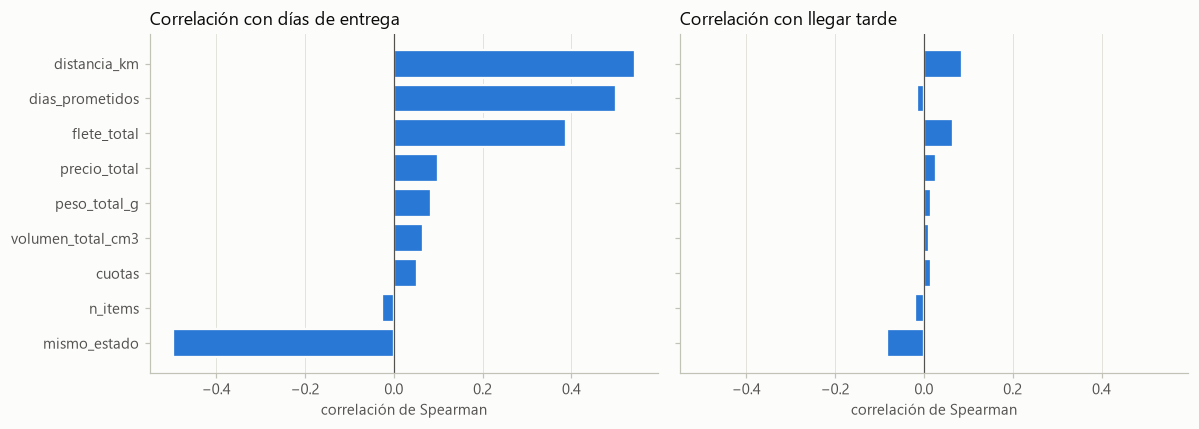

,dias_entrega,tarde
distancia_km,0.54,0.08
dias_prometidos,0.50,-0.02
flete_total,0.39,0.07
precio_total,0.10,0.03
peso_total_g,0.08,0.02
volumen_total_cm3,0.07,0.01
cuotas,0.05,0.02
n_items,-0.03,-0.02
mismo_estado,-0.50,-0.08


Correlación entre las variables relacionadas con la distancia:


,distancia_km,mismo_estado,dias_prometidos,flete_total
distancia_km,1.00,-0.76,0.63,0.58
mismo_estado,-0.76,1.00,-0.60,-0.55
dias_prometidos,0.63,-0.60,1.00,0.48
flete_total,0.58,-0.55,0.48,1.00


In [25]:
# Correlación de cada variable numérica con los días de entrega y con llegar tarde (misma escala en los dos gráficos)
numericas = ["distancia_km", "mismo_estado", "dias_prometidos", "flete_total", "precio_total",
             "peso_total_g", "volumen_total_cm3", "n_items", "cuotas"]
corr = entregados[numericas + ["dias_entrega", "tarde"]].corr(method="spearman")
orden = corr.loc[numericas, "dias_entrega"].sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True, sharex=True)
for a, objetivo, titulo in [(ax[0], "dias_entrega", "Correlación con días de entrega"),
                            (ax[1], "tarde", "Correlación con llegar tarde")]:
    valores = corr.loc[orden, objetivo]
    a.barh(valores.index, valores.values, color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5)
    a.axvline(0, color=TINTA_2, linewidth=0.8)
    a.set(title=titulo, xlabel="correlación de Spearman")
    a.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
display(corr.loc[numericas, ["dias_entrega", "tarde"]].sort_values("dias_entrega", ascending=False))
print("Correlación entre las variables relacionadas con la distancia:")
corr.loc[["distancia_km", "mismo_estado", "dias_prometidos", "flete_total"],
         ["distancia_km", "mismo_estado", "dias_prometidos", "flete_total"]]

**¿Qué vemos?** (Los dos gráficos tienen la misma escala para poder compararlos.)

- **Días de entrega:** las variables más relacionadas son la distancia (0,54), los días prometidos (0,50) y el flete (0,39). `mismo_estado` tiene una relación negativa (−0,50): si el vendedor y el cliente están en el mismo estado, el pedido llega antes. El precio, el peso, el volumen y la cantidad de productos casi no influyen.
- **Llegar tarde:** ninguna variable numérica pasa de 0,1. El retraso depende más de **dónde y cuándo** se hizo la compra, como vimos en 5.4. Por eso creemos que el modelo de clasificación va a ser el más difícil de los tres.
- **Variables repetidas:** la distancia, `mismo_estado`, los días prometidos y el flete están muy relacionados entre sí (entre 0,48 y 0,76), porque todos dependen de qué tan lejos va el pedido. Esto no es un problema para los modelos de árboles, pero en un modelo lineal puede hacer que los resultados sean inestables. Por eso, si usamos un modelo lineal, va a ser uno con regularización (Ridge), que controla ese efecto.

## 6. Serie de tiempo: ¿cuántos pedidos hay por día?

Para el tercer modelo contamos **todos los pedidos que se hicieron cada día**, incluidos los cancelados, porque lo que queremos predecir es la demanda (cuántas compras habrá) y no las entregas.

In [26]:
# Contamos los pedidos de cada día y revisamos el principio y el final de los datos
diario = o.set_index("order_purchase_timestamp").resample("D").size().rename("pedidos")
print("Primeros días con datos:")
print(diario[diario > 0].head(8).to_string())
print("\nDesde el 05-01-2017:")
print(diario["2017-01-05":"2017-01-12"].to_string())
print(f"Días sin pedidos entre el 05-01-2017 y el 19-08-2018: {(diario['2017-01-05':'2018-08-19'] == 0).sum()}")
print("\nÚltimos días de agosto de 2018:")
print(diario["2018-08-15":"2018-08-31"].to_string())

Primeros días con datos:
order_purchase_timestamp
2016-09-04     1
2016-09-05     1
2016-09-13     1
2016-09-15     1
2016-10-02     1
2016-10-03     8
2016-10-04    63
2016-10-05    47

Desde el 05-01-2017:
order_purchase_timestamp
2017-01-05    32
2017-01-06     4
2017-01-07     4
2017-01-08     6
2017-01-09     5
2017-01-10     6
2017-01-11    12
2017-01-12    13
Freq: D
Días sin pedidos entre el 05-01-2017 y el 19-08-2018: 0

Últimos días de agosto de 2018:
order_purchase_timestamp
2018-08-15    288
2018-08-16    320
2018-08-17    257
2018-08-18    198
2018-08-19    204
2018-08-20    256
2018-08-21    243
2018-08-22    187
2018-08-23    144
2018-08-24     99
2018-08-25     69
2018-08-26     73
2018-08-27     67
2018-08-28     44
2018-08-29     14
2018-08-30      4
2018-08-31      1
Freq: D


**¿Qué decidimos?** Usar los datos del **5 de enero de 2017 al 19 de agosto de 2018 (592 días)**.

- **Inicio:** en 2016 hay días sueltos con 1 pedido, un grupo de pedidos en octubre y casi nada en noviembre y diciembre. Desde el 5 de enero de 2017 hay pedidos todos los días, sin huecos.
- **Final:** desde el 20–22 de agosto de 2018 los pedidos bajan día a día hasta casi cero. No es que la gente dejara de comprar: es el efecto del corte de los datos que vimos en la limpieza. Cortamos el domingo 19 de agosto para no incluir esa caída falsa y terminar con una semana completa.

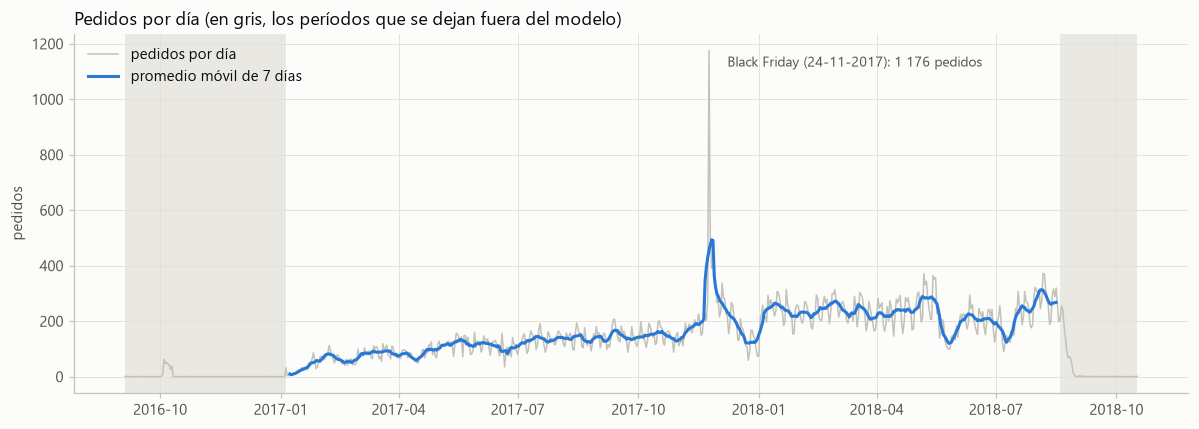

Serie para modelar: 05-01-2017 a 19-08-2018, 592 días, mediana 153 pedidos por día


In [27]:
# Gráfico de la serie completa; en gris, los períodos que dejamos fuera
INICIO, FIN = "2017-01-05", "2018-08-19"
serie = diario[INICIO:FIN]

fig, ax = plt.subplots(figsize=(11, 4))
ax.axvspan(diario.index[0], pd.Timestamp(INICIO), color=GRILLA, alpha=0.7, linewidth=0)
ax.axvspan(pd.Timestamp(FIN), diario.index[-1], color=GRILLA, alpha=0.7, linewidth=0)
ax.plot(diario.index, diario, color=EJE, linewidth=1, label="pedidos por día")
ax.plot(serie.index, serie.rolling(7, center=True).mean(), color=AZUL, linewidth=2, label="promedio móvil de 7 días")
pico = serie.idxmax()
ax.annotate(f"Black Friday ({pico:%d-%m-%Y}): {miles(serie.max())} pedidos", xy=(pico, serie.max()),
            xytext=(12, -4), textcoords="offset points", va="top", color=TINTA_2, fontsize=9)
ax.set(title="Pedidos por día (en gris, los períodos que se dejan fuera del modelo)", ylabel="pedidos")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(f"Serie para modelar: {serie.index[0]:%d-%m-%Y} a {serie.index[-1]:%d-%m-%Y}, {len(serie)} días, "
      f"mediana {serie.median():.0f} pedidos por día")

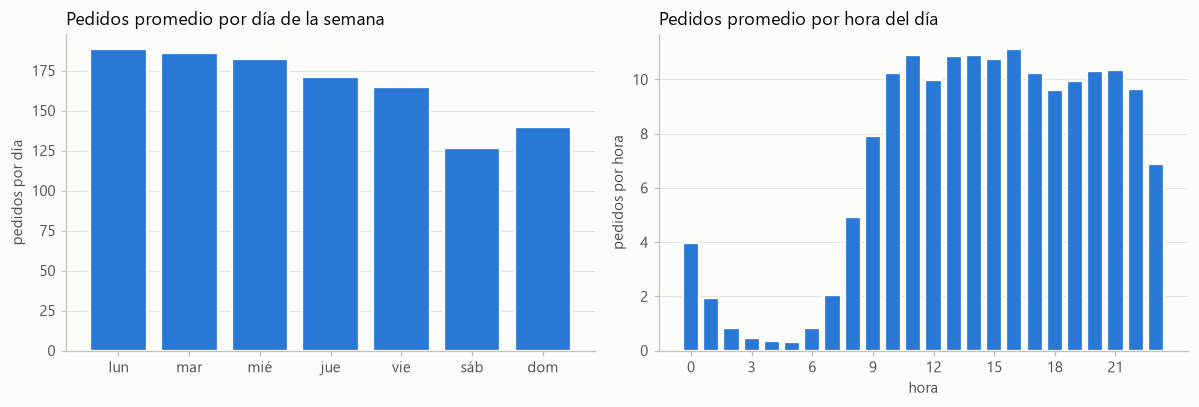

In [28]:
# Promedio de pedidos según el día de la semana y la hora del día
compras = o["order_purchase_timestamp"]
en_ventana = compras.between(pd.Timestamp(INICIO), pd.Timestamp(FIN) + pd.Timedelta(days=1), inclusive="left")
por_dia = serie.groupby(serie.index.day_of_week).mean()
por_hora = compras[en_ventana].dt.hour.value_counts().sort_index() / len(serie)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"], por_dia.values, color=AZUL,
          edgecolor=SUPERFICIE, linewidth=1.5)
ax[0].set(title="Pedidos promedio por día de la semana", ylabel="pedidos por día")
ax[1].bar(por_hora.index, por_hora.values, color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5)
ax[1].set(title="Pedidos promedio por hora del día", xlabel="hora", ylabel="pedidos por hora", xticks=range(0, 24, 3))
for a in ax:
    a.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **La tienda crece:** de menos de 50 pedidos diarios a comienzos de 2017 pasa a unos 200–300 en 2018. A esto se le llama **tendencia**.
- **Black Friday:** el 24 de noviembre de 2017 hubo 1.176 pedidos, casi 6 veces lo normal en esas semanas. Es un día especial que el modelo tiene que tratar aparte para que no confunda el resto de la serie.
- **Patrón semanal:** el lunes es el día con más pedidos y el sábado el que menos.
- **Patrón por hora:** casi nadie compra entre las 2 y las 6 de la mañana; la mayoría de las compras ocurre entre las 10 y las 22 horas.

### Separamos la serie en partes

Para entender mejor la serie usamos la **descomposición STL**, que la separa en tres partes:

- **Tendencia:** hacia dónde va la serie a largo plazo (si sube o baja).
- **Estacionalidad semanal:** el patrón que se repite cada 7 días.
- **Residuo:** lo que queda y no se explica con lo anterior (el "ruido").

También usamos la **prueba ADF**, que dice si la serie es **estacionaria**, es decir, si su nivel se mantiene estable en el tiempo. Varios modelos de series de tiempo necesitan que la serie sea estacionaria.

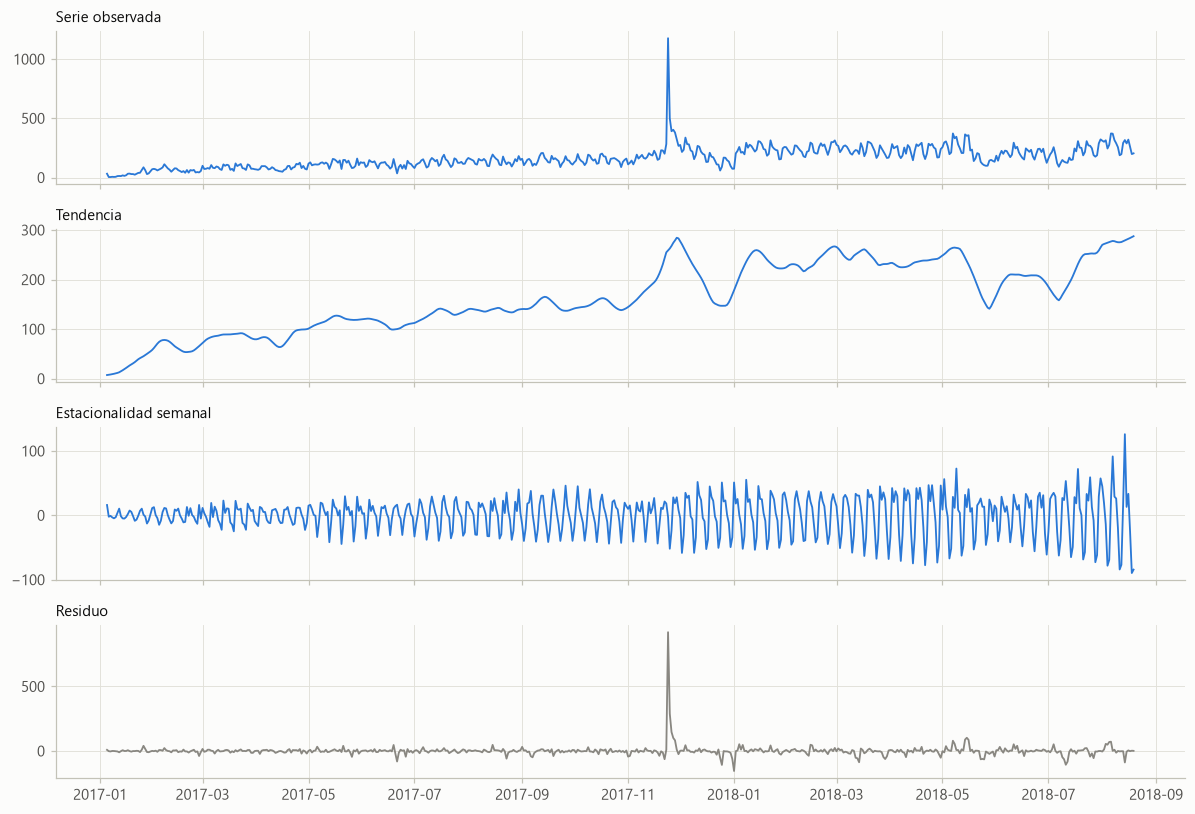

Fuerza de la tendencia: 0.72 · fuerza del patrón semanal: 0.23 (0 = nada, 1 = todo)
Prueba ADF, serie original: p = 0.0684 -> no es estacionaria (es estacionaria si p < 0.05)
Prueba ADF, diferencia entre un día y el anterior: p = 0.0000 -> es estacionaria (es estacionaria si p < 0.05)


In [29]:
# Descomposición STL con un ciclo de 7 días y prueba ADF
stl = STL(serie, period=7, robust=True).fit()
componentes = [(serie, "Serie observada", AZUL), (stl.trend, "Tendencia", AZUL),
               (stl.seasonal, "Estacionalidad semanal", AZUL), (stl.resid, "Residuo", TENUE)]
fig, ax = plt.subplots(4, 1, figsize=(11, 7.5), sharex=True)
for a, (comp, titulo, color) in zip(ax, componentes):
    a.plot(comp.index, comp, color=color, linewidth=1.2)
    a.set_title(titulo, fontsize=10)
plt.tight_layout()
plt.show()

fuerza_tendencia = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
fuerza_semanal = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Fuerza de la tendencia: {fuerza_tendencia:.2f} · fuerza del patrón semanal: {fuerza_semanal:.2f} "
      "(0 = nada, 1 = todo)")
for nombre, valores in [("serie original", serie), ("diferencia entre un día y el anterior", serie.diff().dropna())]:
    p_valor = adfuller(valores)[1]
    print(f"Prueba ADF, {nombre}: p = {p_valor:.4f} -> "
          f"{'es estacionaria' if p_valor < 0.05 else 'no es estacionaria'} (es estacionaria si p < 0.05)")

**¿Qué vemos?**

- La **tendencia** es lo que más pesa (0,72 en una escala de 0 a 1). Tiene una baja en las fiestas de fin de 2017 y otra a fines de mayo de 2018, que coincide con la huelga nacional de camioneros en Brasil.
- El **patrón semanal** pesa menos (0,23), y se hace más grande a medida que la tienda vende más. Por eso conviene trabajar con el logaritmo de los pedidos, para que el patrón quede más parejo.
- El **residuo** es pequeño, salvo en Black Friday. Esto confirma que ese día hay que tratarlo como un evento especial.
- **¿Es estacionaria?** La serie original no lo es (p = 0,068 en la prueba ADF), porque tiene tendencia. Pero si trabajamos con la **diferencia** entre un día y el anterior, sí lo es (p < 0,001). Esto nos va a servir para elegir el modelo de serie de tiempo.

## 7. Diccionario de datos y archivos que guardamos

Para evitar la **fuga de datos** seguimos una regla: una variable solo puede usarse para predecir si se conoce **en el momento de la compra**. Por eso no usamos la fecha de aprobación del pago, la fecha en que el pedido salió con el transportista, la fecha real de entrega ni la reseña: todas pasan después de comprar.

**`pedidos_entregados.csv`** (para los modelos de regresión y clasificación)

| Columna | Qué significa | ¿Se sabe al comprar? | ¿Para qué sirve? |
|---|---|---|---|
| `order_id` | código del pedido | sí | identificar el pedido |
| `order_purchase_timestamp` | fecha y hora de la compra | sí | separar los datos por fecha |
| `order_estimated_delivery_date` | fecha de entrega que promete Olist | sí | calcular `tarde` y `dias_prometidos` |
| `order_delivered_customer_date` | fecha real de entrega | **no** | solo para calcular lo que queremos predecir |
| `customer_state`, `seller_state` | estado del cliente y del vendedor | sí | puede usarse para predecir |
| `customer_zip_code_prefix`, `seller_zip_code_prefix` | código postal (CEP) | sí | calcular la distancia en la aplicación |
| `distancia_km` | distancia en línea recta entre vendedor y cliente | sí | puede usarse para predecir |
| `mismo_estado` | 1 si están en el mismo estado | sí | puede usarse para predecir |
| `categoria` | categoría del producto principal | sí | puede usarse para predecir |
| `n_items`, `n_productos`, `n_vendedores` | tamaño del pedido | sí | puede usarse para predecir |
| `precio_total`, `flete_total` | precio de los productos y del envío (en reales) | sí | puede usarse para predecir |
| `peso_total_g`, `volumen_total_cm3` | peso y volumen del pedido | sí | puede usarse para predecir |
| `tipo_pago`, `cuotas` | forma de pago | sí | puede usarse para predecir |
| `mes`, `dia_semana`, `hora` | cuándo se hizo la compra | sí | puede usarse para predecir |
| `dias_prometidos` | días que promete Olist | sí | puede usarse para predecir |
| **`dias_entrega`** | días que tardó el pedido | no | **lo que predice el modelo de regresión** |
| **`tarde`** | 1 si llegó después del día prometido | no | **lo que predice el modelo de clasificación** |

**`pedidos_diarios.csv`** (para la serie de tiempo): la fecha y la cantidad de pedidos de cada día.

Para la aplicación guardamos dos archivos más en la carpeta `models/`:

- **`geo_cep.csv`**: las coordenadas y el estado de cada código postal. Con ella la aplicación calcula la distancia y sabe en qué estado están el cliente y el vendedor a partir de los códigos postales que escriba el usuario.
- **`opciones.json`**: las listas que muestra el formulario (categorías, formas de pago) y valores típicos para rellenarlo.

In [30]:
# Guardamos los datos limpios en data/processed
columnas = ["order_id", "order_purchase_timestamp", "order_estimated_delivery_date", "order_delivered_customer_date",
            "customer_state", "customer_zip_code_prefix", "seller_state", "seller_zip_code_prefix",
            "distancia_km", "mismo_estado", "categoria", "n_items", "n_productos", "n_vendedores",
            "precio_total", "flete_total", "peso_total_g", "volumen_total_cm3", "tipo_pago", "cuotas",
            "mes", "dia_semana", "hora", "dias_prometidos", "dias_entrega", "tarde"]
entregados[columnas].to_csv(PROCESSED / "pedidos_entregados.csv", index=False)
serie.to_csv(PROCESSED / "pedidos_diarios.csv", index_label="fecha")

# Y lo que necesita la aplicación en models/
geo_cep.to_csv(MODELOS / "geo_cep.csv")
un_producto = entregados[entregados["n_items"] == 1]  # valores típicos de un pedido de un solo producto
opciones = {
    "categorias": entregados["categoria"].value_counts().index.tolist(),
    "tipos_pago": entregados["tipo_pago"].value_counts().index.tolist(),
    "estados": sorted(entregados["customer_state"].unique().tolist()),
    "valores_tipicos": {
        "precio_unitario": round(float(un_producto["precio_total"].median()), 2),
        "flete_total": round(float(un_producto["flete_total"].median()), 2),
        "peso_unitario_g": round(float(un_producto["peso_total_g"].median())),
        "largo_cm": round(float(prod["product_length_cm"].median())),
        "alto_cm": round(float(prod["product_height_cm"].median())),
        "ancho_cm": round(float(prod["product_width_cm"].median())),
        "dias_prometidos": round(float(entregados["dias_prometidos"].median())),
    },
}
(MODELOS / "opciones.json").write_text(json.dumps(opciones, indent=2, ensure_ascii=False), encoding="utf-8")

for archivo in [*sorted(PROCESSED.glob("*.csv")), MODELOS / "geo_cep.csv", MODELOS / "opciones.json"]:
    print(f"{archivo.parent.name}/{archivo.name}: {archivo.stat().st_size / 1e6:.2f} MB")
print("Valores típicos para el formulario:", opciones["valores_tipicos"])

processed/geo_cep.csv: 0.87 MB
processed/pedidos_diarios.csv: 0.01 MB
processed/pedidos_entregados.csv: 21.08 MB
models/geo_cep.csv: 0.93 MB
models/opciones.json: 0.00 MB
Valores típicos para el formulario: {'precio_unitario': 79.99, 'flete_total': 16.39, 'peso_unitario_g': 700, 'largo_cm': 25, 'alto_cm': 13, 'ancho_cm': 20, 'dias_prometidos': 23}


## 8. Conclusiones

**¿Qué datos quedaron listos?**

- `pedidos_entregados.csv`: 89.713 pedidos entregados entre enero de 2017 y julio de 2018.
- `pedidos_diarios.csv`: 592 días de pedidos, del 5 de enero de 2017 al 19 de agosto de 2018.
- `models/geo_cep.csv`: coordenadas y estado de 19.011 códigos postales, para la aplicación.
- `models/opciones.json`: las listas y los valores típicos del formulario de la aplicación.

**Resumen de lo que hicimos en la limpieza**

1. Leímos los códigos postales como texto para no perder los ceros del inicio.
2. Dejamos una coordenada por código postal (la mediana) y quitamos 31 puntos que caían fuera de Brasil.
3. Corregimos el estado de 35 vendedores que no coincidía con su código postal.
4. Completamos los productos sin categoría (610) y sin medidas (2).
5. Nos quedamos solo con pedidos entregados y con fechas lógicas, y sacamos los de 2016 y los de agosto de 2018.
6. Dejamos los pedidos atípicos, porque son retrasos reales.

**Lo que aprendimos para cada modelo**

| Modelo | ¿Qué predice? | Lo que nos mostraron los datos | Qué vamos a hacer |
|---|---|---|---|
| Regresión | días de entrega | Hay pedidos que tardan muchísimo; la distancia y la ubicación son lo que más influye | Entrenar con el logaritmo de los días y comparar un modelo lineal con modelos de árboles. Compararlo con responder siempre la mediana |
| Clasificación | si llega tarde | Solo el 6,8% llega tarde, y depende más de la región y de la época que de las variables numéricas | Usar métricas pensadas para clases desbalanceadas (F1, *recall*, AUC) y compararlo con responder siempre "a tiempo" |
| Serie de tiempo | pedidos por día | La tienda crece, hay un patrón semanal y un pico enorme en Black Friday | Trabajar con diferencias o con los valores de días anteriores, marcar el Black Friday y compararlo con usar el valor de hace 7 días |

**Dos reglas que vamos a respetar en todos los modelos:**

- Separar los datos **por fecha** (entrenar con el pasado y probar con el futuro), porque el comportamiento cambia con el tiempo.
- Usar solo variables que se conocen **en el momento de la compra**, para evitar la fuga de datos.